# Seasonal (Cycle) Plot

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Overlays each year as its own line on a shared month axis, or groups values by season. Seasonal patterns can be compared year against year, which a long continuous line hides.

## When to use

- Data has a strong seasonal cycle (retail, energy demand, flu cases, tourism)
- Ask whether this year's season is unusual compared with past years

## Avoid when

- There is no repeating cycle
- Many years would overlap into an unreadable bundle (highlight the latest year)

## Alternatives

- Line chart
- Calendar heatmap
- Small multiples by year

## Design tips

- Gray out past years and color the current year

## Example

Monthly electricity demand for six years, highlighting the most recent year.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(6)
years = range(2019, 2025)
months = np.arange(1, 13)
rows = []
for i, y in enumerate(years):
    demand = 300 + 4 * i + 60 * np.cos((months - 1.3) / 12 * 2 * np.pi) ** 2 \
        + 25 * np.exp(-((months - 7.5) / 1.2) ** 2) + rng.normal(0, 6, 12)
    rows += [(y, m, d) for m, d in zip(months, demand)]
df = pd.DataFrame(rows, columns=["year", "month", "demand_gwh"])
df.head()

,year,month,demand_gwh
0,2019,1,364.850390
1,2019,2,362.953293
2,2019,3,308.442918
3,2019,4,300.645566
4,2019,5,314.113794


### Plot

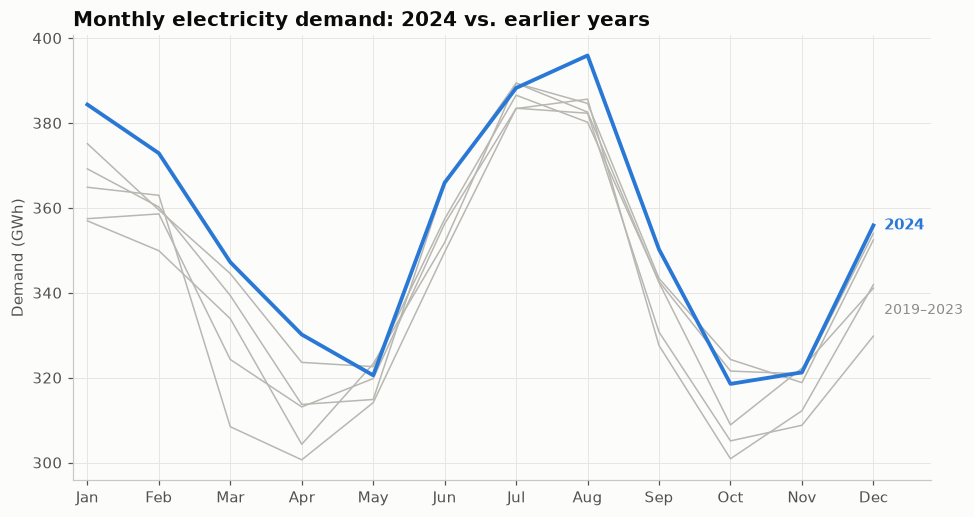

In [3]:
import calendar
latest = df["year"].max()
fig, ax = plt.subplots(figsize=(9, 4.8))
for y, g in df.groupby("year"):
    is_latest = y == latest
    ax.plot(g["month"], g["demand_gwh"], color=PALETTE[0] if is_latest else GRAY,
            linewidth=2.5 if is_latest else 1, zorder=3 if is_latest else 2)
    if is_latest:
        ax.text(12.15, g["demand_gwh"].iloc[-1], str(y), va="center",
                color=PALETTE[0], fontweight="bold")
ax.text(12.15, df[df["year"] < latest].query("month == 12")["demand_gwh"].mean() - 8,
        f"{df['year'].min()}–{latest - 1}", va="center", fontsize=9, color="#8c8b86")
ax.set_xticks(months, [calendar.month_abbr[m] for m in months])
ax.set_xlim(0.8, 12.8)
ax.set_ylabel("Demand (GWh)")
ax.set_title(f"Monthly electricity demand: {latest} vs. earlier years")
fig.tight_layout()
plt.show()

---
Standalone script: [`seasonal_cycle_plot.py`](seasonal_cycle_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)